# INFO2049 Assignement: Language Model

## Librarires

In [1]:
from datasets import load_dataset
import numpy as np
import torch.nn.functional as F
import gensim.downloader as api
import torch
import matplotlib.pyplot as plt
import torch.nn as nn
import nltk
from nltk.tokenize import word_tokenize
import gensim.downloader as api

/opt/miniconda3/envs/NLP/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

Wikipedia dataset from Hugging Face. The columns of the dataset are the following:
- id : the id of the article.
- ulr : the url of the corresponding Wikipedia article.
- title : the title of the corresponding Wikipedia article.
- text : the text of the corresponding article.

We just select a subset of dataset samples because the original dataset size is more than 6.4M articles. Moreover, in this project, the goal is compared the performance of two static embedding strategies (+ the enhancement). Therefore, the goal is not to try to find the model with the highest performance.

In [2]:
subset_size = 100

ds = load_dataset("wikimedia/wikipedia", "20231101.en", split="train")

article_indices = np.random.choice(len(ds), size=subset_size, replace=False).tolist()

ds = ds.select(article_indices)

Perform a word-level tokenization (from https://www.geeksforgeeks.org/nlp/nlp-how-tokenizing-text-sentence-words-works/)

In [3]:
def tokenization(ds):
    nltk.download("punkt_tab")
    all_tokens = []
    for i in range(len(ds)):
        text = ds[i]["text"]
        tokens = word_tokenize(text, language="english")
        all_tokens.append(tokens)
    return ds.add_column("tokens", all_tokens)

Build the vocabulary from the training data by assigning a unique ID to each word and reserving `<UNK>` for unknown words.

In [4]:
def create_vocab(ds):
    word_to_id = {"<UNK>": 0}

    for tokens in ds["tokens"]:
        for word in tokens:
            if word not in word_to_id:
                word_to_id[word] = len(word_to_id)

    vocab_size = len(word_to_id)
    return vocab_size, word_to_id

Convert each article’s tokens into word IDs using the training vocabulary, mapping unknown words to `<UNK>`.

In [5]:
def encoding(ds, word_to_id):
    all_token_ids = []

    for article in ds:
        article_ids = []

        for word in article["tokens"]:
            token_id = word_to_id.get(word, word_to_id["<UNK>"])
            article_ids.append(token_id)

        all_token_ids.append(article_ids)

    return ds.add_column("token_ids", all_token_ids)

Create the training sequence in the same way as the stock market prediction

In [6]:
def create_sequence(ds, lookback):
    X, y = [], []

    for article in ds:
        ids = article["token_ids"]

        for j in range(len(ids) - lookback):
            X.append(ids[j : j + lookback])
            y.append(ids[j + lookback])

    return np.array(X), np.array(y)

Split : 70%/30% 

In [7]:
ds = tokenization(ds)
split = ds.train_test_split(test_size=0.3)
ds_train = split["train"]
ds_test = split["test"]

[nltk_data] Downloading package punkt_tab to /Users/antoi/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
Flattening the indices: 100%|██████████| 100/100 [00:00<00:00, 8957.98 examples/s]


Training set

In [8]:
# Vocabulary -> training data only
vocab_size, word_to_id = create_vocab(ds_train)
ds_train = encoding(ds_train, word_to_id)
X_train, y_train = create_sequence(ds_train, lookback=20)

Flattening the indices: 100%|██████████| 70/70 [00:00<00:00, 15773.14 examples/s]


Test set

In [9]:
ds_test = encoding(ds_test, word_to_id)
X_test, y_test = create_sequence(ds_test, lookback=20)

Flattening the indices: 100%|██████████| 30/30 [00:00<00:00, 6999.45 examples/s]


## Baseline

### Evaluation metrics

- **Cross-entropy:** next-word prediction is a multiclass classification problem. Therefore, the used of the cross entropy is a natural choice. Lower is better

- **Accuracy:** proportion of examples where the most probable word matches the correct next word. Higher is better.

- **Perplexity:** a common metric for next-word prediction that measures uncertainty about the correct words. It measures how uncertain the model is about the correct next words. Unlike accuracy, it considers their predicted probabilities. Lower is better.

Both models are evaluated using the same test set and output vocabulary.

LSTM architecture

In [10]:
class WikipediaLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, vocab_size):
        super().__init__()
        self.vocab_size = vocab_size
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)
        # No need of softmax since we use cross-entropy of Pytoch

    def forward(self, x):
        x, _ = self.lstm(x)
        # x[:, -1, :] because the LSTM returns a predictions for each lookback words also
        return self.fc(x[:, -1, :])

In [11]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cpu


### One-hot encoding

Model training

In [12]:
dataset_train = torch.utils.data.TensorDataset(torch.tensor(X_train, dtype=torch.int64), torch.tensor(y_train, dtype=torch.int64))
dataloader_train = torch.utils.data.DataLoader(dataset_train, batch_size=4, shuffle=True)

model = WikipediaLSTM(input_size=vocab_size, hidden_size=128, num_layers=1, vocab_size=vocab_size)
model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model.train()
EPOCHS = 50

train_loss_list = []

for epoch in range(EPOCHS):
    train_loss = 0
    total_examples = 0
    for batch_x, batch_y in dataloader_train:
        optimizer.zero_grad()
        
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        inputs = F.one_hot(batch_x, num_classes=vocab_size).float()

        predictions = model(inputs)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        batch_size = batch_y.size(0)
        train_loss += loss.item() * batch_size
        total_examples += batch_size

    train_loss_list.append(train_loss / total_examples)
    print(f"Epoch {epoch+1} loss: {train_loss / total_examples:.6f}")

Epoch 1 loss: 7.260582
Epoch 2 loss: 6.119265
Epoch 3 loss: 5.307231
Epoch 4 loss: 4.541373
Epoch 5 loss: 3.831120
Epoch 6 loss: 3.219199
Epoch 7 loss: 2.667804
Epoch 8 loss: 2.196516
Epoch 9 loss: 1.783463
Epoch 10 loss: 1.431642
Epoch 11 loss: 1.133363
Epoch 12 loss: 0.899563
Epoch 13 loss: 0.721401
Epoch 14 loss: 0.587642
Epoch 15 loss: 0.498794
Epoch 16 loss: 0.429134
Epoch 17 loss: 0.369889
Epoch 18 loss: 0.346767
Epoch 19 loss: 0.317886
Epoch 20 loss: 0.297270
Epoch 21 loss: 0.300318
Epoch 22 loss: 0.280676
Epoch 23 loss: 0.272580
Epoch 24 loss: 0.262526
Epoch 25 loss: 0.259089
Epoch 26 loss: 0.256648
Epoch 27 loss: 0.253066
Epoch 28 loss: 0.254238
Epoch 29 loss: 0.248031
Epoch 30 loss: 0.246485
Epoch 31 loss: 0.249174
Epoch 32 loss: 0.248109
Epoch 33 loss: 0.244962
Epoch 34 loss: 0.245724
Epoch 35 loss: 0.247601
Epoch 36 loss: 0.251218
Epoch 37 loss: 0.261322
Epoch 38 loss: 0.257145
Epoch 39 loss: 0.266360
Epoch 40 loss: 0.265261
Epoch 41 loss: 0.273888
Epoch 42 loss: 0.274843
E

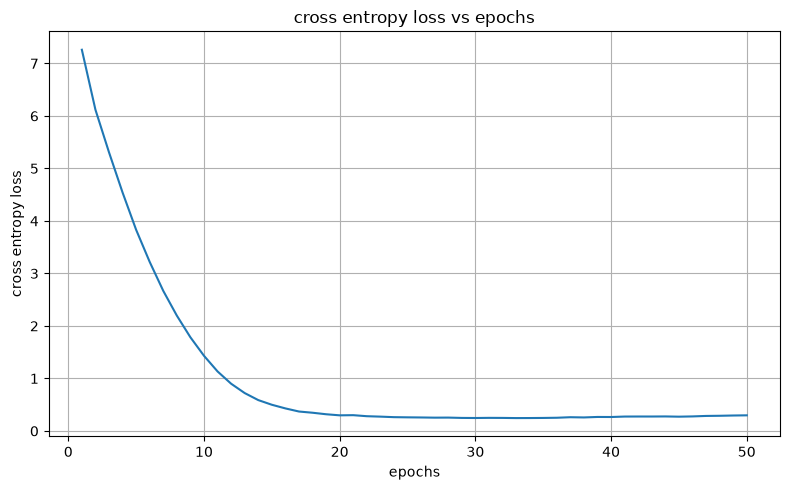

In [13]:
epochs = range(1, len(train_loss_list) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss_list)
plt.xlabel("epochs")
plt.ylabel("cross entropy loss")
plt.title("cross entropy loss vs epochs")
plt.grid()
plt.tight_layout()
plt.show()

Model testing

In [14]:
dataset_test = torch.utils.data.TensorDataset(torch.tensor(X_test, dtype=torch.int64), torch.tensor(y_test, dtype=torch.int64))
dataloader_test = torch.utils.data.DataLoader(dataset_test, batch_size=4, shuffle=True)

model.eval()

total_loss = 0
total_correct = 0
total_examples = 0

with torch.no_grad():
    for batch_x, batch_y in dataloader_test:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        inputs = F.one_hot(batch_x, num_classes=vocab_size).float()

        predictions = model(inputs)

        loss = criterion(predictions, batch_y)

        batch_size = batch_y.size(0)
        total_loss += loss.item() * batch_size

        predicted_ids = predictions.argmax(dim=1)

        for i in range(batch_y.size(0)):
            predicted_word_id = predicted_ids[i].item()
            correct_word_id = batch_y[i].item()

            if predicted_word_id == correct_word_id:
                total_correct += 1
                
        total_examples += batch_size

accuracy = total_correct / total_examples
perplexity = np.exp(total_loss / total_examples)

print(f"Test loss: {total_loss:.6f}")
print(f"Test accuracy: {accuracy:.2f}")
print(f"Test perplexity: {perplexity:.6f}")

Test loss: 131769.769587
Test accuracy: 0.08
Test perplexity: 94301.912021


### Word2Vec

In [15]:
def create_embedding_matrix(word_to_id, word2vec_model, input_size, device):
    vocab_size = len(word_to_id)
    embedding_matrix = torch.zeros(vocab_size, input_size, dtype=torch.float32)

    for word, token_id in word_to_id.items():
        if word in word2vec_model:
            embedding_matrix[token_id] = torch.tensor(word2vec_model[word])

    return embedding_matrix.to(device)

In [16]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
word2vec_model = api.load("word2vec-google-news-300")
input_size = word2vec_model.vector_size
embedding_matrix = create_embedding_matrix(word_to_id, word2vec_model, input_size, device)

Using device: cpu


Model training

In [17]:
dataset_train = torch.utils.data.TensorDataset(torch.tensor(X_train, dtype=torch.int64), torch.tensor(y_train, dtype=torch.int64))
dataloader_train = torch.utils.data.DataLoader(dataset_train, batch_size=4, shuffle=True)

model = WikipediaLSTM(input_size=input_size, hidden_size=128, num_layers=1, vocab_size=vocab_size)
model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model.train()
EPOCHS = 50

train_loss_list = []

for epoch in range(EPOCHS):
    train_loss = 0
    total_examples = 0
    for batch_x, batch_y in dataloader_train:
        optimizer.zero_grad()
        
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        inputs = embedding_matrix[batch_x]

        predictions = model(inputs)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        batch_size = batch_y.size(0)
        train_loss += loss.item() * batch_size
        total_examples += batch_size

    train_loss_list.append(train_loss / total_examples)
    print(f"Epoch {epoch+1} loss: {train_loss / total_examples:.6f}")

Epoch 1 loss: 7.144941
Epoch 2 loss: 6.035587
Epoch 3 loss: 5.298909
Epoch 4 loss: 4.645375
Epoch 5 loss: 4.067266
Epoch 6 loss: 3.554508
Epoch 7 loss: 3.096464
Epoch 8 loss: 2.692844
Epoch 9 loss: 2.338740
Epoch 10 loss: 2.026843
Epoch 11 loss: 1.764026
Epoch 12 loss: 1.545682
Epoch 13 loss: 1.348789
Epoch 14 loss: 1.193014
Epoch 15 loss: 1.065881
Epoch 16 loss: 0.955065
Epoch 17 loss: 0.868135
Epoch 18 loss: 0.799509
Epoch 19 loss: 0.739360
Epoch 20 loss: 0.693814
Epoch 21 loss: 0.647432
Epoch 22 loss: 0.624429
Epoch 23 loss: 0.599010
Epoch 24 loss: 0.573143
Epoch 25 loss: 0.562849
Epoch 26 loss: 0.555925
Epoch 27 loss: 0.537468
Epoch 28 loss: 0.533394
Epoch 29 loss: 0.511127
Epoch 30 loss: 0.487737
Epoch 31 loss: 0.496679
Epoch 32 loss: 0.470924
Epoch 33 loss: 0.481666
Epoch 34 loss: 0.462672
Epoch 35 loss: 0.448187
Epoch 36 loss: 0.447599
Epoch 37 loss: 0.440530
Epoch 38 loss: 0.436609
Epoch 39 loss: 0.431281
Epoch 40 loss: 0.418437
Epoch 41 loss: 0.424387
Epoch 42 loss: 0.413892
E

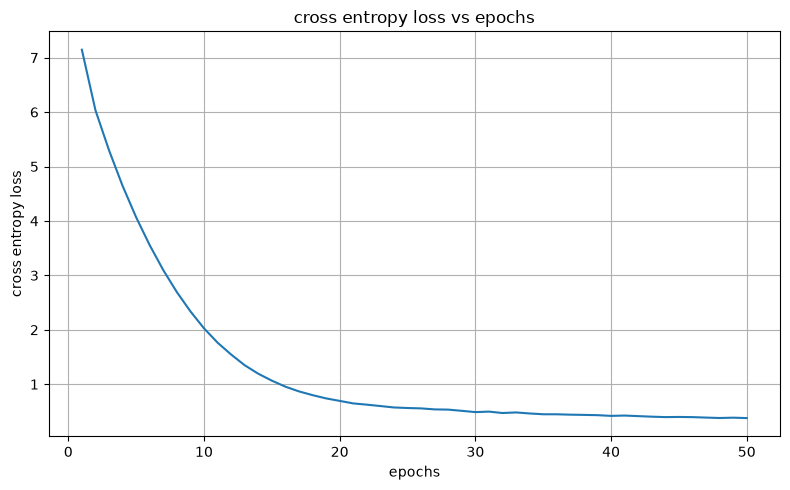

In [18]:
epochs = range(1, len(train_loss_list) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss_list)
plt.xlabel("epochs")
plt.ylabel("cross entropy loss")
plt.title("cross entropy loss vs epochs")
plt.grid()
plt.tight_layout()
plt.show()

Model testing

In [19]:
dataset_test = torch.utils.data.TensorDataset(torch.tensor(X_test, dtype=torch.int64), torch.tensor(y_test, dtype=torch.int64))
dataloader_test = torch.utils.data.DataLoader(dataset_test, batch_size=4, shuffle=True)

model.eval()

total_loss = 0
total_correct = 0
total_examples = 0

with torch.no_grad():
    for batch_x, batch_y in dataloader_test:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        inputs = embedding_matrix[batch_x]

        predictions = model(inputs)

        loss = criterion(predictions, batch_y)

        batch_size = batch_y.size(0)
        total_loss += loss.item() * batch_size

        predicted_ids = predictions.argmax(dim=1)

        for i in range(batch_y.size(0)):
            predicted_word_id = predicted_ids[i].item()
            correct_word_id = batch_y[i].item()

            if predicted_word_id == correct_word_id:
                total_correct += 1
                
        total_examples += batch_size

accuracy = total_correct / total_examples
perplexity = np.exp(total_loss / total_examples)

print(f"Test loss: {total_loss:.6f}")
print(f"Test accuracy: {accuracy:.2f}")
print(f"Test perplexity: {perplexity:.6f}")

Test loss: 142225.481671
Test accuracy: 0.07
Test perplexity: 234013.238763
